In [ ]:
# ==================================================
# 01. CONFIGURACIÓN DEL TRANSFORMER
# ==================================================

from google.colab import drive
from pathlib import Path

import json
import math
import random
import numpy as np
import torch
import torch.nn as nn
import sentencepiece as spm

# Montar Google Drive
drive.mount("/content/drive")

# Reproducibilidad
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Rutas
BASE_DIR = Path(
    "/content/drive/MyDrive/Proyecto_traductor/"
    "traductor_optimizado"
)

CONFIG_DIR = BASE_DIR / "configuracion"
TOKENIZER_DIR = BASE_DIR / "tokenizador"

# Cargar configuración del tokenizador
with open(
    CONFIG_DIR / "tokenizador_config.json",
    "r",
    encoding="utf-8"
) as f:
    tokenizer_config = json.load(f)

# Cargar tokenizador BPE
sp = spm.SentencePieceProcessor(
    model_file=str(TOKENIZER_DIR / "tokenizer.model")
)

# Configuración del Transformer
MODEL_CONFIG = {
    "vocab_size": sp.get_piece_size(),
    "d_model": 256,
    "nhead": 8,
    "num_encoder_layers": 4,
    "num_decoder_layers": 4,
    "dim_feedforward": 1024,
    "dropout": 0.1,
    "max_length": tokenizer_config["max_length"],
    "pad_id": sp.pad_id(),
    "bos_id": sp.bos_id(),
    "eos_id": sp.eos_id()
}

# Dispositivo
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Dispositivo:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "Memoria GPU:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )

print("PyTorch:", torch.__version__)
print("Vocabulario:", sp.get_piece_size())

print("\nCONFIGURACIÓN DEL TRANSFORMER")
print(json.dumps(MODEL_CONFIG, indent=4))

Mounted at /content/drive
Dispositivo: cuda
GPU: Tesla T4
Memoria GPU: 14.56 GB
PyTorch: 2.11.0+cu130
Vocabulario: 16000

CONFIGURACIÓN DEL TRANSFORMER
{
    "vocab_size": 16000,
    "d_model": 256,
    "nhead": 8,
    "num_encoder_layers": 4,
    "num_decoder_layers": 4,
    "dim_feedforward": 1024,
    "dropout": 0.1,
    "max_length": 80,
    "pad_id": 0,
    "bos_id": 2,
    "eos_id": 3
}


In [ ]:
# ==================================================
# 02. EMBEDDINGS Y CODIFICACIÓN POSICIONAL
# ==================================================

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_length=80):
        super().__init__()

        # Posiciones: [max_length, 1]
        position = torch.arange(
            max_length, dtype=torch.float32
        ).unsqueeze(1)

        # Frecuencias sinusoidales
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-math.log(10000.0) / d_model)
        )

        # Matriz de posiciones: [1, max_length, d_model]
        pe = torch.zeros(1, max_length, d_model)

        pe[0, :, 0::2] = torch.sin(position * div_term)
        pe[0, :, 1::2] = torch.cos(position * div_term)

        # Buffer: se mueve con el modelo a GPU,
        # pero no es un parámetro entrenable
        self.register_buffer("pe", pe)

    def forward(self, x):
        # x: [batch_size, seq_len, d_model]
        seq_len = x.size(1)

        if seq_len > self.pe.size(1):
            raise ValueError(
                f"Longitud {seq_len} supera "
                f"el máximo {self.pe.size(1)}"
            )

        return x + self.pe[:, :seq_len, :]


class TokenEmbedding(nn.Module):
    def __init__(self, vocab_size, d_model, pad_id):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=d_model,
            padding_idx=pad_id
        )

        self.scale = math.sqrt(d_model)

    def forward(self, tokens):
        # tokens: [batch_size, seq_len]
        # salida: [batch_size, seq_len, d_model]
        return self.embedding(tokens) * self.scale


# ==================================================
# PRUEBA DE COMPONENTES
# ==================================================

embedding = TokenEmbedding(
    vocab_size=MODEL_CONFIG["vocab_size"],
    d_model=MODEL_CONFIG["d_model"],
    pad_id=MODEL_CONFIG["pad_id"]
).to(DEVICE)

pos_encoding = PositionalEncoding(
    d_model=MODEL_CONFIG["d_model"],
    max_length=MODEL_CONFIG["max_length"]
).to(DEVICE)

# Lote de prueba: 2 oraciones de 12 tokens
tokens_prueba = torch.randint(
    low=4,
    high=MODEL_CONFIG["vocab_size"],
    size=(2, 12),
    device=DEVICE
)

emb = embedding(tokens_prueba)
salida = pos_encoding(emb)

print("Tokens:", tokens_prueba.shape)
print("Embeddings:", emb.shape)
print("Embeddings + posición:", salida.shape)

assert salida.shape == (2, 12, 256)

print("\nComponentes implementados correctamente.")

Tokens: torch.Size([2, 12])
Embeddings: torch.Size([2, 12, 256])
Embeddings + posición: torch.Size([2, 12, 256])

Componentes implementados correctamente.


In [ ]:
# ==================================================
# 03. MODELO TRANSFORMER ENCODER-DECODER
# ==================================================

class TranslationTransformer(nn.Module):

    def __init__(self, config):
        super().__init__()

        self.config = config
        self.pad_id = config["pad_id"]
        d_model = config["d_model"]

        # Embeddings aprendidos desde cero
        self.src_embedding = TokenEmbedding(
            config["vocab_size"], d_model, self.pad_id
        )

        self.tgt_embedding = TokenEmbedding(
            config["vocab_size"], d_model, self.pad_id
        )

        # Codificación posicional
        self.positional_encoding = PositionalEncoding(
            d_model=d_model,
            max_length=config["max_length"]
        )

        self.dropout = nn.Dropout(config["dropout"])

        # Arquitectura encoder-decoder
        self.transformer = nn.Transformer(
            d_model=d_model,
            nhead=config["nhead"],
            num_encoder_layers=config["num_encoder_layers"],
            num_decoder_layers=config["num_decoder_layers"],
            dim_feedforward=config["dim_feedforward"],
            dropout=config["dropout"],
            activation="relu",
            batch_first=True,
            norm_first=False
        )

        # Proyección al vocabulario español
        self.output_layer = nn.Linear(
            d_model, config["vocab_size"]
        )

    def forward(self, src, tgt):

        # src: [batch, src_len]
        # tgt: [batch, tgt_len]

        src_padding_mask = src.eq(self.pad_id)
        tgt_padding_mask = tgt.eq(self.pad_id)

        tgt_len = tgt.size(1)

        # Máscara causal: bloquea posiciones futuras
        causal_mask = nn.Transformer.generate_square_subsequent_mask(
            tgt_len,
            device=tgt.device
        )

        src_emb = self.dropout(
            self.positional_encoding(
                self.src_embedding(src)
            )
        )

        tgt_emb = self.dropout(
            self.positional_encoding(
                self.tgt_embedding(tgt)
            )
        )

        hidden = self.transformer(
            src=src_emb,
            tgt=tgt_emb,
            tgt_mask=causal_mask,
            src_key_padding_mask=src_padding_mask,
            tgt_key_padding_mask=tgt_padding_mask,
            memory_key_padding_mask=src_padding_mask
        )

        logits = self.output_layer(hidden)

        return logits


# Crear modelo
model = TranslationTransformer(MODEL_CONFIG).to(DEVICE)

print("Transformer creado correctamente.")
print("Dispositivo:", next(model.parameters()).device)

Transformer creado correctamente.
Dispositivo: cuda:0


In [ ]:
# ==================================================
# 04. VALIDACIÓN DEL TRANSFORMER Y PARÁMETROS
# ==================================================

# Modo evaluación para realizar una prueba determinista
model.eval()

# Dos oraciones de prueba con diferentes longitudes
oraciones_en = [
    "I want to learn artificial intelligence.",
    "The university is developing a new project."
]

oraciones_es = [
    "Quiero aprender inteligencia artificial.",
    "La universidad está desarrollando un nuevo proyecto."
]

# Tokenizar incluyendo BOS y EOS
def codificar(texto):
    return (
        [sp.bos_id()]
        + sp.encode(texto, out_type=int)
        + [sp.eos_id()]
    )

src_secuencias = [codificar(t) for t in oraciones_en]
tgt_secuencias = [codificar(t) for t in oraciones_es]

# Padding dinámico
from torch.nn.utils.rnn import pad_sequence

src = pad_sequence(
    [torch.tensor(s, dtype=torch.long) for s in src_secuencias],
    batch_first=True,
    padding_value=sp.pad_id()
).to(DEVICE)

tgt = pad_sequence(
    [torch.tensor(s, dtype=torch.long) for s in tgt_secuencias],
    batch_first=True,
    padding_value=sp.pad_id()
).to(DEVICE)

# Teacher forcing: el decoder recibe la secuencia
# española desplazada una posición
tgt_input = tgt[:, :-1]
tgt_expected = tgt[:, 1:]

# Propagación hacia adelante
with torch.no_grad():
    logits = model(src, tgt_input)

# Conteo de parámetros
total_params = sum(p.numel() for p in model.parameters())

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("=" * 50)
print("VALIDACIÓN DEL TRANSFORMER")
print("=" * 50)

print("Entrada EN:", src.shape)
print("Entrada decoder ES:", tgt_input.shape)
print("Salida logits:", logits.shape)
print("Objetivos ES:", tgt_expected.shape)

print("\nPARÁMETROS DEL MODELO")
print(f"Parámetros totales: {total_params:,}")
print(f"Parámetros entrenables: {trainable_params:,}")
print(f"Parámetros no entrenables: {total_params - trainable_params:,}")

# Comprobaciones
assert logits.shape == (
    tgt_input.size(0),
    tgt_input.size(1),
    MODEL_CONFIG["vocab_size"]
)

assert torch.isfinite(logits).all()

print("\nTodas las comprobaciones fueron exitosas.")

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/activation.py:1336: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(


VALIDACIÓN DEL TRANSFORMER
Entrada EN: torch.Size([2, 12])
Entrada decoder ES: torch.Size([2, 10])
Salida logits: torch.Size([2, 10, 16000])
Objetivos ES: torch.Size([2, 10])

PARÁMETROS DEL MODELO
Parámetros totales: 19,677,824
Parámetros entrenables: 19,677,824
Parámetros no entrenables: 0

Todas las comprobaciones fueron exitosas.


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/activation.py:1336: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(


In [ ]:
# ==================================================
# 05. CORREGIR MÁSCARAS DE ATENCIÓN
# ==================================================

def forward_corregido(self, src, tgt):

    src_padding_mask = src.eq(self.pad_id)
    tgt_padding_mask = tgt.eq(self.pad_id)

    tgt_len = tgt.size(1)

    # Máscara causal booleana:
    # True significa posición bloqueada
    causal_mask = torch.triu(
        torch.ones(
            tgt_len,
            tgt_len,
            dtype=torch.bool,
            device=tgt.device
        ),
        diagonal=1
    )

    src_emb = self.dropout(
        self.positional_encoding(self.src_embedding(src))
    )

    tgt_emb = self.dropout(
        self.positional_encoding(self.tgt_embedding(tgt))
    )

    hidden = self.transformer(
        src=src_emb,
        tgt=tgt_emb,
        tgt_mask=causal_mask,
        src_key_padding_mask=src_padding_mask,
        tgt_key_padding_mask=tgt_padding_mask,
        memory_key_padding_mask=src_padding_mask
    )

    return self.output_layer(hidden)


# Actualizar el método sin cambiar los pesos
TranslationTransformer.forward = forward_corregido

# Comprobar que funciona
model.eval()

with torch.no_grad():
    logits = model(src, tgt_input)

assert logits.shape == (
    tgt_input.size(0),
    tgt_input.size(1),
    MODEL_CONFIG["vocab_size"]
)

assert torch.isfinite(logits).all()

print("Máscaras corregidas correctamente.")
print("Tipo de máscara causal: bool")
print("Salida:", logits.shape)
print("Parámetros:", f"{sum(p.numel() for p in model.parameters()):,}")

Máscaras corregidas correctamente.
Tipo de máscara causal: bool
Salida: torch.Size([2, 10, 16000])
Parámetros: 19,677,824


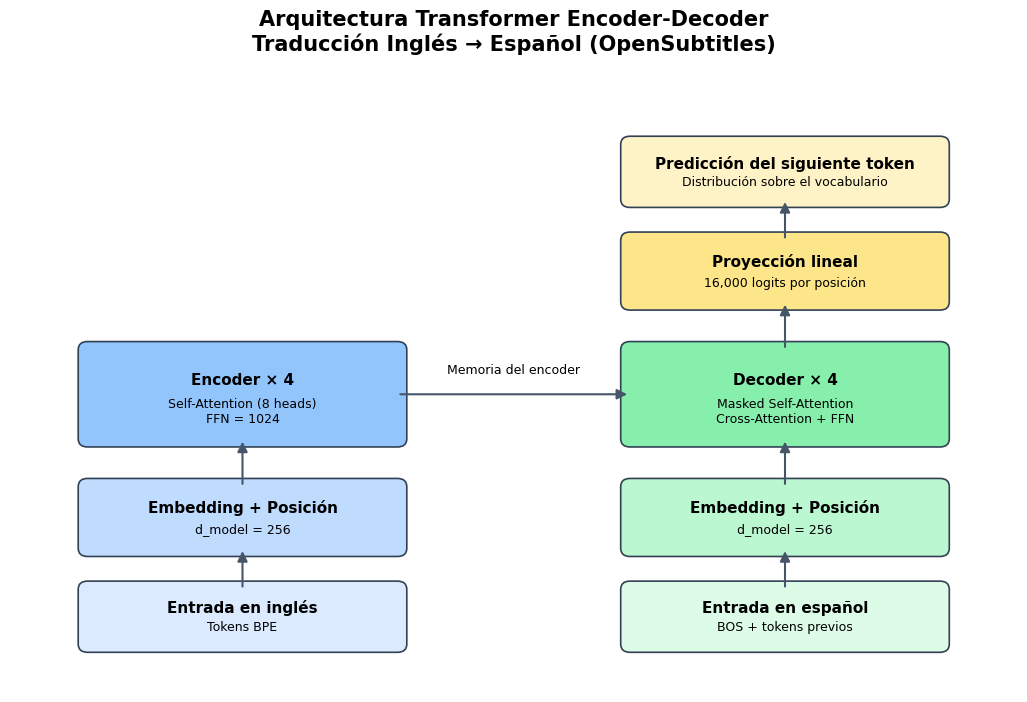

Diagrama guardado en:
/content/drive/MyDrive/Proyecto_traductor/traductor_optimizado/resultados/graficos/arquitectura_transformer.png


In [ ]:
# ==================================================
# 06. DIAGRAMA DE ARQUITECTURA DEL TRANSFORMER
# ==================================================

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

GRAFICOS_DIR = BASE_DIR / "resultados" / "graficos"
GRAFICOS_DIR.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(13, 8))
ax.set_xlim(0, 13)
ax.set_ylim(0, 9)
ax.axis("off")

def bloque(x, y, w, h, titulo, detalle, color):
    rect = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.12",
        facecolor=color,
        edgecolor="#334155",
        linewidth=1.2
    )
    ax.add_patch(rect)
    ax.text(x+w/2, y+h*0.65, titulo,
            ha="center", va="center",
            fontsize=11, fontweight="bold")
    ax.text(x+w/2, y+h*0.3, detalle,
            ha="center", va="center",
            fontsize=9)

def flecha(x1, y1, x2, y2):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="-|>",
        mutation_scale=15,
        linewidth=1.5,
        color="#475569"
    ))

# Encoder
bloque(1, 0.7, 4, 0.8,
       "Entrada en inglés", "Tokens BPE", "#dbeafe")

bloque(1, 2.1, 4, 0.9,
       "Embedding + Posición", "d_model = 256", "#bfdbfe")

bloque(1, 3.7, 4, 1.3,
       "Encoder × 4",
       "Self-Attention (8 heads)\nFFN = 1024",
       "#93c5fd")

flecha(3, 1.5, 3, 2.1)
flecha(3, 3.0, 3, 3.7)

# Decoder
bloque(8, 0.7, 4, 0.8,
       "Entrada en español",
       "BOS + tokens previos", "#dcfce7")

bloque(8, 2.1, 4, 0.9,
       "Embedding + Posición", "d_model = 256", "#bbf7d0")

bloque(8, 3.7, 4, 1.3,
       "Decoder × 4",
       "Masked Self-Attention\nCross-Attention + FFN",
       "#86efac")

flecha(10, 1.5, 10, 2.1)
flecha(10, 3.0, 10, 3.7)

# Conexión encoder-decoder
flecha(5, 4.35, 8, 4.35)
ax.text(6.5, 4.65, "Memoria del encoder",
        ha="center", fontsize=9)

# Salida
bloque(8, 5.7, 4, 0.9,
       "Proyección lineal",
       "16,000 logits por posición", "#fde68a")

bloque(8, 7.2, 4, 0.8,
       "Predicción del siguiente token",
       "Distribución sobre el vocabulario",
       "#fef3c7")

flecha(10, 5.0, 10, 5.7)
flecha(10, 6.6, 10, 7.2)

ax.set_title(
    "Arquitectura Transformer Encoder-Decoder\n"
    "Traducción Inglés → Español (OpenSubtitles)",
    fontsize=15,
    fontweight="bold",
    pad=18
)

fig.savefig(
    GRAFICOS_DIR / "arquitectura_transformer.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Diagrama guardado en:")
print(GRAFICOS_DIR / "arquitectura_transformer.png")

In [ ]:
# ==================================================
# 07. EXPORTAR ARQUITECTURA TRANSFORMER - CORREGIDO
# ==================================================

import json
from pathlib import Path

MODEL_DIR = BASE_DIR / "modelo"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "transformer_model.py"

codigo_modelo = '''
import math
import torch
import torch.nn as nn


class PositionalEncoding(nn.Module):

    def __init__(self, d_model, max_length=80):
        super().__init__()

        position = torch.arange(
            max_length, dtype=torch.float32
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-math.log(10000.0) / d_model)
        )

        pe = torch.zeros(1, max_length, d_model)

        pe[0, :, 0::2] = torch.sin(position * div_term)
        pe[0, :, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe)

    def forward(self, x):
        seq_len = x.size(1)

        if seq_len > self.pe.size(1):
            raise ValueError(
                f"Longitud {seq_len} supera el máximo "
                f"{self.pe.size(1)}"
            )

        return x + self.pe[:, :seq_len, :]


class TokenEmbedding(nn.Module):

    def __init__(self, vocab_size, d_model, pad_id):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=pad_id
        )

        self.scale = math.sqrt(d_model)

    def forward(self, tokens):
        return self.embedding(tokens) * self.scale


class TranslationTransformer(nn.Module):

    def __init__(self, config):
        super().__init__()

        self.config = config
        self.pad_id = config["pad_id"]

        d_model = config["d_model"]

        self.src_embedding = TokenEmbedding(
            config["vocab_size"], d_model, self.pad_id
        )

        self.tgt_embedding = TokenEmbedding(
            config["vocab_size"], d_model, self.pad_id
        )

        self.positional_encoding = PositionalEncoding(
            d_model, config["max_length"]
        )

        self.dropout = nn.Dropout(config["dropout"])

        self.transformer = nn.Transformer(
            d_model=d_model,
            nhead=config["nhead"],
            num_encoder_layers=config["num_encoder_layers"],
            num_decoder_layers=config["num_decoder_layers"],
            dim_feedforward=config["dim_feedforward"],
            dropout=config["dropout"],
            activation="relu",
            batch_first=True,
            norm_first=False,
            enable_nested_tensor=False
        ) if False else nn.Transformer(
            d_model=d_model,
            nhead=config["nhead"],
            num_encoder_layers=config["num_encoder_layers"],
            num_decoder_layers=config["num_decoder_layers"],
            dim_feedforward=config["dim_feedforward"],
            dropout=config["dropout"],
            activation="relu",
            batch_first=True,
            norm_first=False
        )

        self.output_layer = nn.Linear(
            d_model, config["vocab_size"]
        )

    def forward(self, src, tgt):

        src_padding_mask = src.eq(self.pad_id)
        tgt_padding_mask = tgt.eq(self.pad_id)

        tgt_len = tgt.size(1)

        # Máscara causal booleana
        causal_mask = torch.triu(
            torch.ones(
                tgt_len,
                tgt_len,
                dtype=torch.bool,
                device=tgt.device
            ),
            diagonal=1
        )

        src_emb = self.dropout(
            self.positional_encoding(
                self.src_embedding(src)
            )
        )

        tgt_emb = self.dropout(
            self.positional_encoding(
                self.tgt_embedding(tgt)
            )
        )

        hidden = self.transformer(
            src=src_emb,
            tgt=tgt_emb,
            tgt_mask=causal_mask,
            src_key_padding_mask=src_padding_mask,
            tgt_key_padding_mask=tgt_padding_mask,
            memory_key_padding_mask=src_padding_mask
        )

        return self.output_layer(hidden)
'''

# Guardar módulo Python
MODEL_PATH.write_text(codigo_modelo, encoding="utf-8")

# Guardar configuración
CONFIG_PATH = CONFIG_DIR / "modelo_config.json"

with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(MODEL_CONFIG, f, indent=4)

print("Arquitectura guardada correctamente:")
print(MODEL_PATH)

print("\nConfiguración guardada:")
print(CONFIG_PATH)

Arquitectura guardada correctamente:
/content/drive/MyDrive/Proyecto_traductor/traductor_optimizado/modelo/transformer_model.py

Configuración guardada:
/content/drive/MyDrive/Proyecto_traductor/traductor_optimizado/configuracion/modelo_config.json


In [ ]:
# ==================================================
# 08. VALIDAR MODELO EXPORTADO
# ==================================================

import sys
import importlib

sys.path.insert(0, str(MODEL_DIR))

import transformer_model
importlib.reload(transformer_model)

modelo_prueba = transformer_model.TranslationTransformer(
    MODEL_CONFIG
).to(DEVICE)

modelo_prueba.eval()

with torch.no_grad():
    salida = modelo_prueba(src, tgt_input)

parametros = sum(
    p.numel() for p in modelo_prueba.parameters()
)

assert salida.shape == (
    tgt_input.size(0),
    tgt_input.size(1),
    MODEL_CONFIG["vocab_size"]
)

assert torch.isfinite(salida).all()
assert parametros == 19_677_824

print("Importación: CORRECTA")
print("Forward pass: CORRECTO")
print("Salida:", salida.shape)
print("Parámetros:", f"{parametros:,}")
print("Modelo listo para entrenamiento.")

Importación: CORRECTA
Forward pass: CORRECTO
Salida: torch.Size([2, 10, 16000])
Parámetros: 19,677,824
Modelo listo para entrenamiento.


In [ ]:
# ==================================================
# 09. VALIDACIÓN DE RETROPROPAGACIÓN
# ==================================================

import torch.nn.functional as F

# Modelo exportado, inicializado desde cero
modelo_prueba.train()

# Optimizador temporal para validar el entrenamiento
optimizer_test = torch.optim.AdamW(
    modelo_prueba.parameters(),
    lr=1e-4
)

optimizer_test.zero_grad(set_to_none=True)

# 1. Forward pass
logits = modelo_prueba(src, tgt_input)

# 2. Calcular pérdida ignorando tokens PAD
loss = F.cross_entropy(
    logits.reshape(-1, MODEL_CONFIG["vocab_size"]),
    tgt_expected.reshape(-1),
    ignore_index=MODEL_CONFIG["pad_id"]
)

# 3. Backward pass
loss.backward()

# 4. Verificar gradientes
gradientes_validos = all(
    torch.isfinite(p.grad).all().item()
    for p in modelo_prueba.parameters()
    if p.grad is not None
)

parametros_con_gradiente = sum(
    p.grad is not None
    for p in modelo_prueba.parameters()
)

assert torch.isfinite(loss).item()
assert gradientes_validos
assert parametros_con_gradiente > 0

# 5. Actualización de parámetros
optimizer_test.step()

print("=" * 45)
print("VALIDACIÓN DE ENTRENAMIENTO")
print("=" * 45)
print(f"Loss inicial: {loss.item():.4f}")
print(f"Parámetros con gradiente: {parametros_con_gradiente}")
print(f"Gradientes finitos: {gradientes_validos}")
print("Actualización AdamW: CORRECTA")
print("\nTransformer preparado para entrenamiento.")

VALIDACIÓN DE ENTRENAMIENTO
Loss inicial: 9.7695
Parámetros con gradiente: 128
Gradientes finitos: True
Actualización AdamW: CORRECTA

Transformer preparado para entrenamiento.
